In [6]:
!pip install opencv-python

   ---------------------------------------- 0.0/40.2 MB ? eta -:--:--
   - -------------------------------------- 1.3/40.2 MB 9.5 MB/s eta 0:00:05
   -- ------------------------------------- 2.9/40.2 MB 8.3 MB/s eta 0:00:05
   ---- ----------------------------------- 4.7/40.2 MB 8.5 MB/s eta 0:00:05
   ------ --------------------------------- 6.8/40.2 MB 8.7 MB/s eta 0:00:04
   -------- ------------------------------- 8.9/40.2 MB 9.1 MB/s eta 0:00:04
   ---------- ----------------------------- 11.0/40.2 MB 9.3 MB/s eta 0:00:04
   ------------- -------------------------- 13.1/40.2 MB 9.3 MB/s eta 0:00:03
   -------------- ------------------------- 14.9/40.2 MB 9.3 MB/s eta 0:00:03
   ---------------- ----------------------- 16.8/40.2 MB 9.2 MB/s eta 0:00:03
   ------------------ --------------------- 18.6/40.2 MB 9.2 MB/s eta 0:00:03
   -------------------- ------------------- 20.7/40.2 MB 9.1 MB/s eta 0:00:03
   --------------------- ------------------ 22.0/40.2 MB 9.1 MB/s eta 0:00:03

In [11]:
import os

os.listdir("Sample (1)")

['.ipynb_checkpoints', 'Sample']

In [13]:
import os

for root, dirs, files in os.walk("Sample (1)"):
    print(f"\n📁 {root}")
    
    for d in dirs:
        print("  [DIR] ", d)

    for f in files:
        print("  [FILE]", f)


📁 Sample (1)
  [DIR]  .ipynb_checkpoints
  [DIR]  Sample

📁 Sample (1)\.ipynb_checkpoints

📁 Sample (1)\Sample
  [DIR]  .ipynb_checkpoints
  [DIR]  01.원천데이터
  [DIR]  02.라벨링데이터

📁 Sample (1)\Sample\.ipynb_checkpoints

📁 Sample (1)\Sample\01.원천데이터
  [DIR]  .ipynb_checkpoints
  [DIR]  스토킹
  [DIR]  싸움
  [DIR]  이륜 이동수단 인도 주행
  [DIR]  이륜 이동수단 헬멧 미착용
  [DIR]  전동킥보드 2인 이상 주행
  [DIR]  침입

📁 Sample (1)\Sample\01.원천데이터\.ipynb_checkpoints

📁 Sample (1)\Sample\01.원천데이터\스토킹
  [DIR]  .ipynb_checkpoints
  [DIR]  특정 구역 내 지속 배회
  [DIR]  특정 인물을 뒤따라가며 배회

📁 Sample (1)\Sample\01.원천데이터\스토킹\.ipynb_checkpoints

📁 Sample (1)\Sample\01.원천데이터\스토킹\특정 구역 내 지속 배회
  [DIR]  .ipynb_checkpoints
  [DIR]  lo_e1281

📁 Sample (1)\Sample\01.원천데이터\스토킹\특정 구역 내 지속 배회\.ipynb_checkpoints

📁 Sample (1)\Sample\01.원천데이터\스토킹\특정 구역 내 지속 배회\lo_e1281
  [FILE] lo_e1281_c1.mp4
  [FILE] lo_e1281_c2.mp4

📁 Sample (1)\Sample\01.원천데이터\스토킹\특정 인물을 뒤따라가며 배회
  [DIR]  .ipynb_checkpoints
  [DIR]  fp_e1520

📁 Sample (1)\Sample\01.원천데이터\스토킹\특정 인물을 

In [15]:
import json

json_path = r"Sample (1)\Sample\02.라벨링데이터\스토킹\특정 인물을 뒤따라가며 배회\fp_e1520\fp_e1520.json"

with open(json_path, encoding="utf-8") as f:
    data = json.load(f)

print(data.keys())

dict_keys(['videos', 'annotations'])


In [16]:
print(json.dumps(data, indent=2, ensure_ascii=False)[:5000])

{
  "videos": [
    {
      "filename": "fp_e1520_c1.mp4",
      "width": 1920,
      "height": 1080,
      "date": "2025-09-03",
      "time": "17:43:19",
      "length": 30.73,
      "cctv_distribution": "P1",
      "cctv_camera": "CDO-DB200IRX",
      "cctv_angle": "A180",
      "source": "or",
      "view": "c1"
    },
    {
      "filename": "fp_e1520_c2.mp4",
      "width": 1920,
      "height": 1080,
      "date": "2025-09-03",
      "time": "17:43:16",
      "length": 30.97,
      "cctv_distribution": "P1",
      "cctv_camera": "CDO-P236XEA1",
      "cctv_angle": "A180",
      "source": "or",
      "view": "c2"
    }
  ],
  "annotations": {
    "event_class": "특정 인물을 뒤따라가며 배회",
    "question": "이 영상에서 '특정 인물을 뒤따라가며 배회' 현상이 나타났는가? 그 판단을 뒷받침하는 프레임·객체 근거는 무엇인가?",
    "caption": {
      "c1": {
        "caption_text": "'특정 인물을 뒤따라가며 배회' 상황으로 분류된 객체 상황 3개가 11.7초 동안 연속적으로 관찰되었음.",
        "cot": {
          "1단계": "사람1이 화면 중앙 도로에서 화면 상단 방향으로 이동하고 있으며 그 뒤로 사람2가 따라가고 있음",
          "2단

In [17]:
import os
import glob

video_index = {}

for path in glob.glob(
    r"Sample (1)\Sample\01.원천데이터\**\*.mp4",
    recursive=True
):
    filename = os.path.basename(path)

    video_index[filename] = path

print(f"videos = {len(video_index)}")

videos = 22


In [18]:
print(video_index["fp_e1520_c1.mp4"])

Sample (1)\Sample\01.원천데이터\스토킹\특정 인물을 뒤따라가며 배회\fp_e1520\fp_e1520_c1.mp4


In [19]:
json_files = glob.glob(
    r"Sample (1)\Sample\02.라벨링데이터\**\*.json",
    recursive=True
)

print(len(json_files))

11


In [20]:
import cv2
import json
import os

json_path = r"Sample (1)\Sample\02.라벨링데이터\스토킹\특정 인물을 뒤따라가며 배회\fp_e1520\fp_e1520.json"

with open(json_path, encoding="utf-8") as f:
    data = json.load(f)

video_name = data["videos"][0]["filename"]

video_path = video_index[video_name]

print(video_path)

cap = cv2.VideoCapture(video_path)

frame_id = data["annotations"]["evidence"]["c1"]["frame_id"][0]

cap.set(cv2.CAP_PROP_POS_FRAMES, frame_id)

ret, frame = cap.read()

print("frame shape =", frame.shape)

cap.release()

Sample (1)\Sample\01.원천데이터\스토킹\특정 인물을 뒤따라가며 배회\fp_e1520\fp_e1520_c1.mp4
frame shape = (1080, 1920, 3)


In [21]:
import cv2

cv2.imwrite("test_frame.jpg", frame)

True

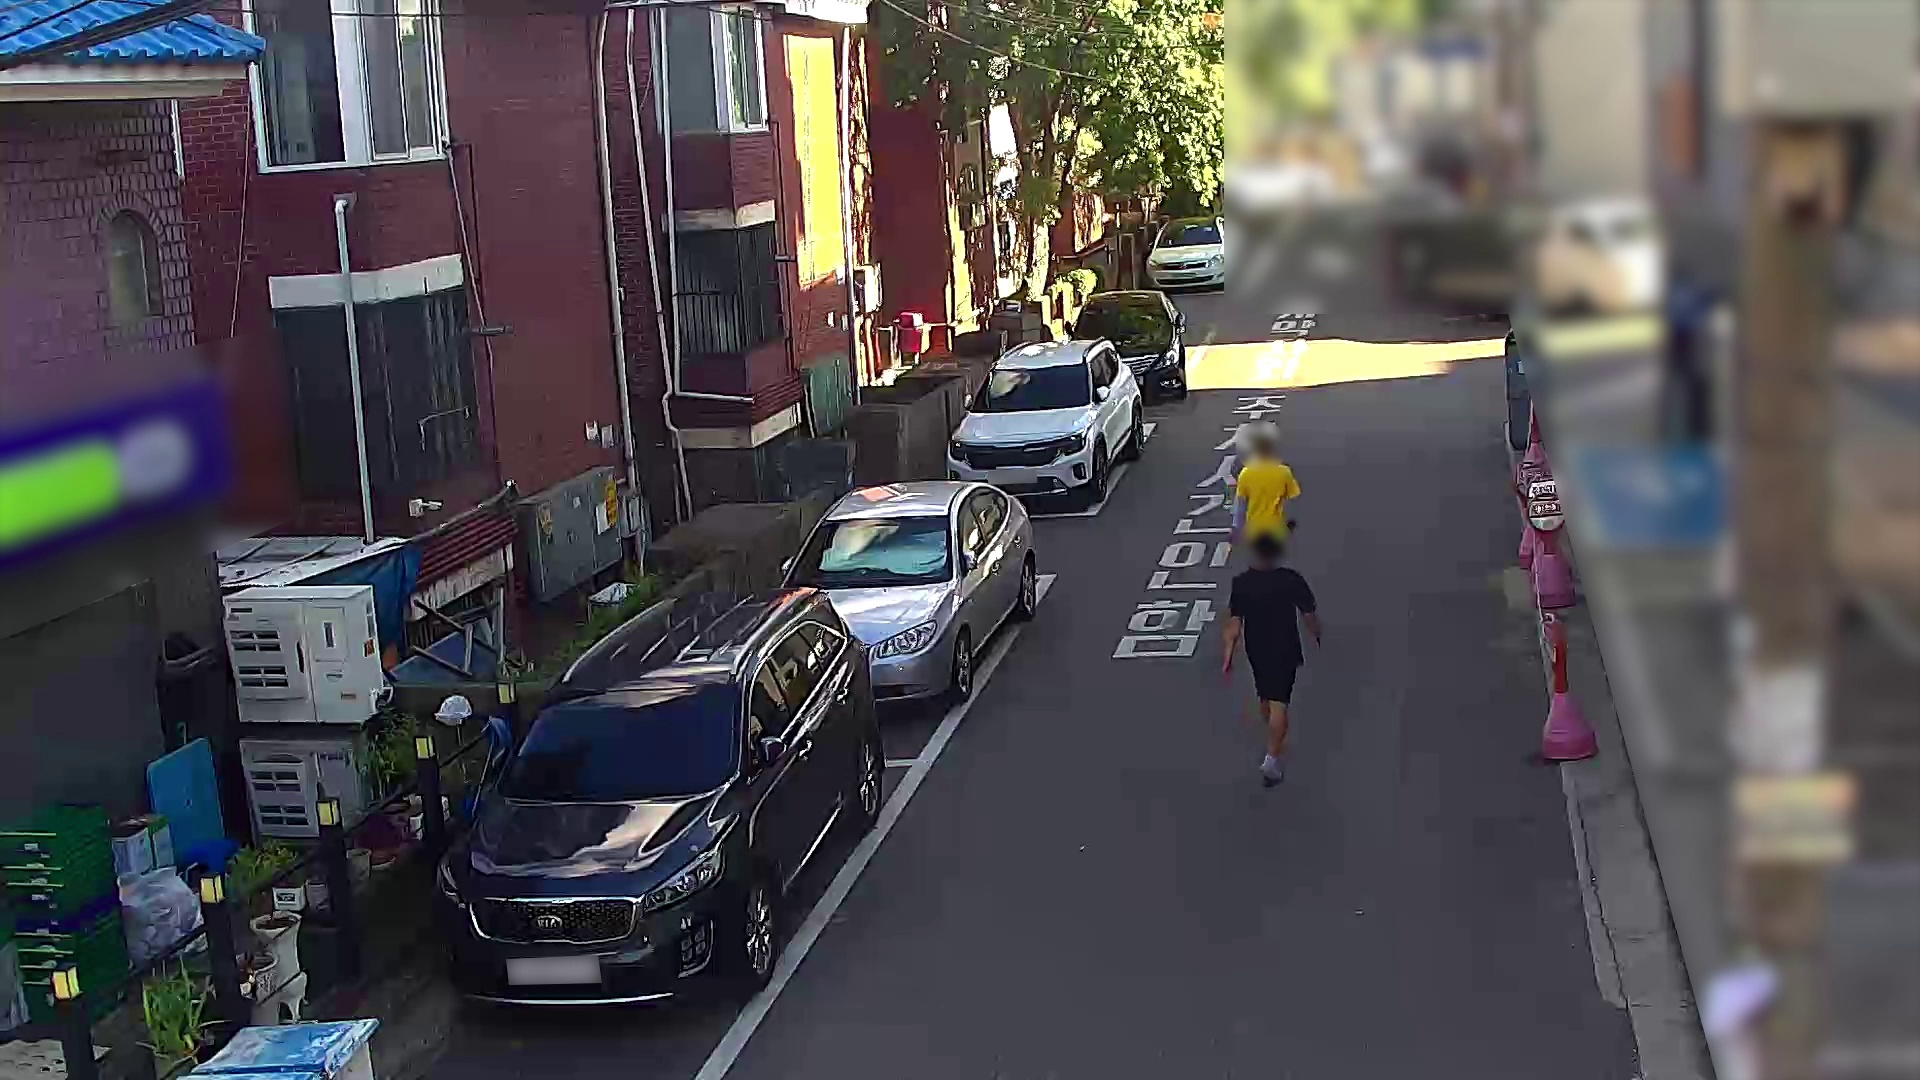

In [22]:
from IPython.display import Image

Image("test_frame.jpg")

In [23]:
bbox = data["annotations"]["evidence"]["c1"]["obj_bbox"][0]

x1,y1,x2,y2 = bbox

crop = frame[y1:y2, x1:x2]

cv2.imwrite("test_crop.jpg", crop)

True

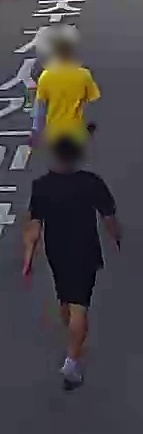

In [24]:
Image("test_crop.jpg")

In [25]:
import os
import cv2
import json
import glob
import traceback

from tqdm import tqdm

# =====================================================
# 실제 데이터셋 루트
# =====================================================

DATA_ROOT = r"Sample (1)\Sample"

VIDEO_ROOT = os.path.join(DATA_ROOT, "01.원천데이터")
LABEL_ROOT = os.path.join(DATA_ROOT, "02.라벨링데이터")

# =====================================================
# 출력
# =====================================================

OUTPUT_DIR = "output"

FRAME_DIR = os.path.join(OUTPUT_DIR, "frames")
CROP_DIR = os.path.join(OUTPUT_DIR, "crops")
DEBUG_DIR = os.path.join(OUTPUT_DIR, "debug")

os.makedirs(FRAME_DIR, exist_ok=True)
os.makedirs(CROP_DIR, exist_ok=True)
os.makedirs(DEBUG_DIR, exist_ok=True)

# =====================================================
# VIDEO INDEX 생성
# =====================================================

print("[INFO] Building video index...")

video_index = {}

for path in glob.glob(
    os.path.join(VIDEO_ROOT, "**", "*.mp4"),
    recursive=True
):

    filename = os.path.basename(path)

    video_index[filename] = path

print(f"[INFO] videos found: {len(video_index)}")

# =====================================================
# JSON 탐색
# =====================================================

json_files = glob.glob(
    os.path.join(LABEL_ROOT, "**", "*.json"),
    recursive=True
)

print(f"[INFO] json found: {len(json_files)}")

# =====================================================
# metadata
# =====================================================

metadata = []

# =====================================================
# JSON 순회
# =====================================================

for json_idx, json_path in enumerate(json_files):

    print("\n" + "=" * 70)
    print(f"[JSON] {json_idx+1}/{len(json_files)}")
    print(json_path)

    try:

        with open(json_path, encoding="utf-8") as f:
            data = json.load(f)

        annotations = data["annotations"]

        event_class = annotations.get("event_class", "")
        question = annotations.get("question", "")
        answer = annotations.get("answer", "")

        videos_info = data["videos"]

        # =================================================
        # c1 / c2 영상 처리
        # =================================================

        for video_info in videos_info:

            video_name = video_info["filename"]
            view = video_info["view"]

            if video_name not in video_index:

                print(f"[WARNING] missing video: {video_name}")
                continue

            video_path = video_index[video_name]

            print(f"\n[VIDEO] {video_name}")

            cap = cv2.VideoCapture(video_path)

            if not cap.isOpened():

                print("[ERROR] video open fail")
                continue

            fps = cap.get(cv2.CAP_PROP_FPS)

            if view not in annotations["evidence"]:

                cap.release()
                continue

            evidence = annotations["evidence"][view]

            frame_ids = evidence["frame_id"]
            obj_ids = evidence["obj_id"]
            bboxes = evidence["obj_bbox"]
            labels = evidence["obj_label"]

            cot_steps = annotations["caption"][view]["cot"]

            # =============================================
            # frame loop
            # =============================================

            for idx in tqdm(range(len(frame_ids)),
                            desc=video_name):

                try:

                    frame_id = frame_ids[idx]

                    bbox = bboxes[idx]

                    obj_id = obj_ids[idx]

                    label = labels[idx]

                    cot_key = f"{idx+1}단계"

                    caption = cot_steps.get(
                        cot_key,
                        ""
                    )

                    # ------------------------------------
                    # frame read
                    # ------------------------------------

                    cap.set(
                        cv2.CAP_PROP_POS_FRAMES,
                        frame_id
                    )

                    ret, frame = cap.read()

                    if not ret:
                        continue

                    # ------------------------------------
                    # frame 저장
                    # ------------------------------------

                    base_name = video_name.replace(
                        ".mp4",
                        ""
                    )

                    frame_file = (
                        f"{base_name}_{frame_id}_frame.jpg"
                    )

                    frame_path = os.path.join(
                        FRAME_DIR,
                        frame_file
                    )

                    cv2.imwrite(
                        frame_path,
                        frame
                    )

                    # ------------------------------------
                    # bbox 보호
                    # ------------------------------------

                    x1, y1, x2, y2 = bbox

                    h, w = frame.shape[:2]

                    x1 = max(0, x1)
                    y1 = max(0, y1)

                    x2 = min(w, x2)
                    y2 = min(h, y2)

                    crop = frame[y1:y2, x1:x2]

                    if crop.size == 0:
                        continue

                    # ------------------------------------
                    # crop 저장
                    # ------------------------------------

                    crop_file = (
                        f"{base_name}_{frame_id}_crop.jpg"
                    )

                    crop_path = os.path.join(
                        CROP_DIR,
                        crop_file
                    )

                    cv2.imwrite(
                        crop_path,
                        crop
                    )

                    # ------------------------------------
                    # debug
                    # ------------------------------------

                    debug_img = frame.copy()

                    cv2.rectangle(
                        debug_img,
                        (x1, y1),
                        (x2, y2),
                        (0,255,0),
                        3
                    )

                    cv2.putText(
                        debug_img,
                        str(obj_id),
                        (x1, y1-10),
                        cv2.FONT_HERSHEY_SIMPLEX,
                        1,
                        (0,255,0),
                        2
                    )

                    debug_file = (
                        f"{base_name}_{frame_id}_debug.jpg"
                    )

                    debug_path = os.path.join(
                        DEBUG_DIR,
                        debug_file
                    )

                    cv2.imwrite(
                        debug_path,
                        debug_img
                    )

                    # ------------------------------------
                    # metadata
                    # ------------------------------------

                    timestamp = (
                        frame_id / fps
                        if fps > 0
                        else 0
                    )

                    sample = {

                        "frame_image": frame_path,

                        "crop_image": crop_path,

                        "debug_image": debug_path,

                        "video_name": video_name,

                        "view": view,

                        "frame_id": int(frame_id),

                        "timestamp_sec": float(timestamp),

                        "event_class": event_class,

                        "caption": caption,

                        "question": question,

                        "answer": answer,

                        "obj_id": str(obj_id),

                        "obj_label": label,

                        "bbox": bbox
                    }

                    metadata.append(sample)

                except Exception as e:

                    print(
                        f"[FRAME ERROR] "
                        f"{video_name} "
                        f"{frame_id}"
                    )

                    print(e)

            cap.release()

    except Exception:

        traceback.print_exc()

# =====================================================
# metadata 저장
# =====================================================

metadata_path = os.path.join(
    OUTPUT_DIR,
    "metadata.json"
)

with open(
    metadata_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        metadata,
        f,
        ensure_ascii=False,
        indent=4
    )

print("\n" + "=" * 70)
print("[DONE]")
print(f"Total samples: {len(metadata)}")
print(f"Metadata: {metadata_path}")

[INFO] Building video index...
[INFO] videos found: 22
[INFO] json found: 11

[JSON] 1/11
Sample (1)\Sample\02.라벨링데이터\스토킹\특정 구역 내 지속 배회\lo_e1281\lo_e1281.json

[VIDEO] lo_e1281_c1.mp4


lo_e1281_c1.mp4: 100%|███████████████████████████████████████████████████████████████████| 3/3 [00:00<00:00,  5.68it/s]



[VIDEO] lo_e1281_c2.mp4


lo_e1281_c2.mp4: 100%|███████████████████████████████████████████████████████████████████| 3/3 [00:00<00:00,  6.08it/s]



[JSON] 2/11
Sample (1)\Sample\02.라벨링데이터\스토킹\특정 인물을 뒤따라가며 배회\fp_e1520\fp_e1520.json

[VIDEO] fp_e1520_c1.mp4


...


[JSON] 11/11
Sample (1)\Sample\02.라벨링데이터\침입\비정상적인 경로로의 침범\ab_e0457\ab_e0457.json

[VIDEO] ab_e0457_c1.mp4


ab_e0457_c1.mp4: 100%|███████████████████████████████████████████████████████████████████| 3/3 [00:00<00:00,  5.45it/s]



[VIDEO] ab_e0457_c2.mp4


ab_e0457_c2.mp4: 100%|███████████████████████████████████████████████████████████████████| 3/3 [00:00<00:00,  8.44it/s]


[DONE]
Total samples: 66
Metadata: output\metadata.json


In [5]:
!pip install ultralytics

   ---------------------------------------- 0.0/1.3 MB ? eta -:--:--
   ---------------------------------------- 1.3/1.3 MB 8.1 MB/s  0:00:00
   ---------------------------------------- 0.0/833.4 kB ? eta -:--:--
   ---------------------------------------- 833.4/833.4 kB 8.4 MB/s  0:00:00
   ---------------------------------------- 0.0/52.0 MB ? eta -:--:--
   - -------------------------------------- 1.8/52.0 MB 9.9 MB/s eta 0:00:06
   -- ------------------------------------- 3.7/52.0 MB 8.9 MB/s eta 0:00:06
   ---- ----------------------------------- 5.5/52.0 MB 9.0 MB/s eta 0:00:06
   ----- ---------------------------------- 7.3/52.0 MB 8.9 MB/s eta 0:00:06
   ------- -------------------------------- 9.2/52.0 MB 8.8 MB/s eta 0:00:05
   -------- ------------------------------- 11.0/52.0 MB 8.9 MB/s eta 0:00:05
   ---------- ----------------------------- 13.4/52.0 MB 9.1 MB/s eta 0:00:05
   ----------- ---------------------------- 15.2/52.0 MB 9.1 MB/s eta 0:00:05
   ------------- ----

In [6]:
from ultralytics import YOLO

model = YOLO("yolov8n.pt")
print("성공")

Creating new Ultralytics Settings v0.0.6 file  
View Ultralytics Settings with 'yolo settings' or at 'C:\Users\\AppData\Roaming\Ultralytics\settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
성공


In [8]:
import os
import cv2
import json
import glob

from tqdm import tqdm
from ultralytics import YOLO

# =====================================================
# 데이터셋 경로
# =====================================================

DATA_ROOT = r"Sample (1)\Sample\01.원천데이터"

VIDEO_LIST = glob.glob(
    os.path.join(DATA_ROOT, "**", "*.mp4"),
    recursive=True
)

print(f"[INFO] 발견된 영상 수: {len(VIDEO_LIST)}")

if len(VIDEO_LIST) == 0:
    raise RuntimeError("mp4 파일을 찾을 수 없습니다.")

# =====================================================
# 출력 폴더
# =====================================================

OUTPUT_DIR = "output_part2"

os.makedirs(OUTPUT_DIR, exist_ok=True)

# =====================================================
# 관심 객체
# =====================================================

TARGET_CLASSES = {
    0: "person",
    1: "bicycle",
    2: "car",
    3: "motorcycle",
    5: "bus",
    7: "truck"
}

# =====================================================
# YOLO 모델
# =====================================================

model = YOLO("yolov8n.pt")

# =====================================================
# 전체 결과 저장
# =====================================================

all_results = []

# =====================================================
# 모든 영상 처리
# =====================================================

for VIDEO_PATH in VIDEO_LIST:

    print("\n" + "=" * 60)
    print("[VIDEO]", VIDEO_PATH)

    video_name = os.path.basename(VIDEO_PATH)
    video_id = os.path.splitext(video_name)[0]

    cap = cv2.VideoCapture(VIDEO_PATH)

    if not cap.isOpened():

        print("[ERROR] 영상 열기 실패")
        continue

    fps = cap.get(cv2.CAP_PROP_FPS)

    width = int(
        cap.get(cv2.CAP_PROP_FRAME_WIDTH)
    )

    height = int(
        cap.get(cv2.CAP_PROP_FRAME_HEIGHT)
    )

    total_frames = int(
        cap.get(cv2.CAP_PROP_FRAME_COUNT)
    )

    output_video_path = os.path.join(
        OUTPUT_DIR,
        f"{video_id}_tracked.mp4"
    )

    fourcc = cv2.VideoWriter_fourcc(*"mp4v")

    writer = cv2.VideoWriter(
        output_video_path,
        fourcc,
        fps,
        (width, height)
    )

    frame_id = 0

    with tqdm(
        total=total_frames,
        desc=video_id
    ) as pbar:

        while True:

            ret, frame = cap.read()

            if not ret:
                break

            results = model.track(
                frame,
                persist=True,
                tracker="bytetrack.yaml",
                conf=0.25,
                iou=0.5,
                verbose=False
            )

            result = results[0]

            if result.boxes is not None:

                boxes = result.boxes

                for box in boxes:

                    cls_id = int(box.cls[0])

                    if cls_id not in TARGET_CLASSES:
                        continue

                    conf = float(box.conf[0])

                    x1, y1, x2, y2 = map(
                        int,
                        box.xyxy[0]
                    )

                    if box.id is None:
                        track_id = -1
                    else:
                        track_id = int(box.id[0])

                    class_name = TARGET_CLASSES[
                        cls_id
                    ]

                    time_sec = (
                        frame_id / fps
                        if fps > 0
                        else 0
                    )

                    # ---------------------------------
                    # JSON 저장용
                    # ---------------------------------

                    all_results.append({

                        "video_name": video_name,

                        "frame_id": frame_id,

                        "time_sec": round(
                            time_sec,
                            3
                        ),

                        "track_id": track_id,

                        "class_id": cls_id,

                        "class_name": class_name,

                        "confidence": round(
                            conf,
                            4
                        ),

                        "bbox": [
                            x1,
                            y1,
                            x2,
                            y2
                        ]
                    })

                    # ---------------------------------
                    # 시각화
                    # ---------------------------------

                    label = (
                        f"{class_name} "
                        f"ID:{track_id} "
                        f"{conf:.2f}"
                    )

                    cv2.rectangle(
                        frame,
                        (x1, y1),
                        (x2, y2),
                        (0, 255, 0),
                        2
                    )

                    cv2.putText(
                        frame,
                        label,
                        (
                            x1,
                            max(y1 - 10, 20)
                        ),
                        cv2.FONT_HERSHEY_SIMPLEX,
                        0.6,
                        (0, 255, 0),
                        2
                    )

            writer.write(frame)

            frame_id += 1

            pbar.update(1)

    cap.release()
    writer.release()

    print(
        f"[DONE] 저장 완료: {output_video_path}"
    )

# =====================================================
# JSON 저장
# =====================================================

OUTPUT_JSON = os.path.join(
    OUTPUT_DIR,
    "tracking_result.json"
)

with open(
    OUTPUT_JSON,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        all_results,
        f,
        ensure_ascii=False,
        indent=2
    )

print("\n" + "=" * 60)
print("[DONE]")
print("JSON:", OUTPUT_JSON)
print("총 객체 수:", len(all_results))

[INFO] 발견된 영상 수: 22

[VIDEO] Sample (1)\Sample\01.원천데이터\스토킹\특정 구역 내 지속 배회\lo_e1281\lo_e1281_c1.mp4


lo_e1281_c1:   0%|                                                                             | 0/909 [00:00<?, ?it/s]

requirements: Ultralytics requirement ['lap>=0.5.12'] not found, attempting AutoUpdate...
   ---------------------------------------- 0.0/1.5 MB ? eta -:--:--
   ---------------------------------------- 1.5/1.5 MB 11.0 MB/s  0:00:00

[notice] A new release of pip is available: 26.1.1 -> 26.1.2
[notice] To update, run: C:\Users\\AppData\Local\Programs\Python\Python313\python.exe -m pip install --upgrade pip

requirements: AutoUpdate success  3.0s
WARNING requirements: Restart runtime or rerun command for updates to take effect



lo_e1281_c1: 100%|███████████████████████████████████████████████████████████████████| 909/909 [00:54<00:00, 16.81it/s]


[DONE] 저장 완료: output_part2\lo_e1281_c1_tracked.mp4

[VIDEO] Sample (1)\Sample\01.원천데이터\스토킹\특정 구역 내 지속 배회\lo_e1281\lo_e1281_c2.mp4


...

[DONE] 저장 완료: output_part2\bl_e0272_c2_tracked.mp4

[VIDEO] Sample (1)\Sample\01.원천데이터\침입\비정상적인 경로로의 침범\ab_e0457\ab_e0457_c1.mp4


ab_e0457_c1: 100%|███████████████████████████████████████████████████████████████████| 900/900 [00:56<00:00, 16.06it/s]


[DONE] 저장 완료: output_part2\ab_e0457_c1_tracked.mp4

[VIDEO] Sample (1)\Sample\01.원천데이터\침입\비정상적인 경로로의 침범\ab_e0457\ab_e0457_c2.mp4


ab_e0457_c2: 100%|███████████████████████████████████████████████████████████████████| 900/900 [00:57<00:00, 15.72it/s]


[DONE] 저장 완료: output_part2\ab_e0457_c2_tracked.mp4

[DONE]
JSON: output_part2\tracking_result.json
총 객체 수: 88004


In [1]:
import os
import cv2
import json
import glob

from tqdm import tqdm
from ultralytics import YOLO

In [2]:
DATA_ROOT = r"Sample (1)\Sample\01.원천데이터"

OUTPUT_DIR = "output"

DETECTION_DIR = os.path.join(
    OUTPUT_DIR,
    "detections"
)

os.makedirs(
    DETECTION_DIR,
    exist_ok=True
)

print("OUTPUT:", DETECTION_DIR)

OUTPUT: output\detections


In [14]:
model = YOLO("yolov8n.pt")

print("YOLO Loaded")

YOLO Loaded


In [15]:
FRAME_INTERVAL = 2

CONF_THRESHOLD = 0.25

TARGET_FOLDERS = [

    "이륜 이동수단 인도 주행",

    "이륜 이동수단 헬멧 미착용"
]

video_files = []

for folder in TARGET_FOLDERS:

    target_path = os.path.join(
        DATA_ROOT,
        folder
    )

    files = glob.glob(
        os.path.join(
            target_path,
            "**",
            "*.mp4"
        ),
        recursive=True
    )

    video_files.extend(files)

print("videos found:", len(video_files))

for v in video_files:
    print(v)

videos found: 10
Sample (1)\Sample\01.원천데이터\이륜 이동수단 인도 주행\오토바이 인도 주행\ms_e3500\ms_e3500_c1.mp4
Sample (1)\Sample\01.원천데이터\이륜 이동수단 인도 주행\오토바이 인도 주행\ms_e3500\ms_e3500_c2.mp4
Sample (1)\Sample\01.원천데이터\이륜 이동수단 인도 주행\자전거 인도 주행\bs_e4387\bs_e4387_c1.mp4
Sample (1)\Sample\01.원천데이터\이륜 이동수단 인도 주행\자전거 인도 주행\bs_e4387\bs_e4387_c2.mp4
Sample (1)\Sample\01.원천데이터\이륜 이동수단 인도 주행\전동킥보드 인도 주행\es_e3768\es_e3768_c1.mp4
Sample (1)\Sample\01.원천데이터\이륜 이동수단 인도 주행\전동킥보드 인도 주행\es_e3768\es_e3768_c2.mp4
Sample (1)\Sample\01.원천데이터\이륜 이동수단 헬멧 미착용\이륜 이동수단 운전자 1인 헬멧 미착용\md_e2122\md_e2122_c1.mp4
Sample (1)\Sample\01.원천데이터\이륜 이동수단 헬멧 미착용\이륜 이동수단 운전자 1인 헬멧 미착용\md_e2122\md_e2122_c2.mp4
Sample (1)\Sample\01.원천데이터\이륜 이동수단 헬멧 미착용\이륜 이동수단 탑승자 일부 또는 전체 헬멧 미착용\mp_e2730\mp_e2730_c1.mp4
Sample (1)\Sample\01.원천데이터\이륜 이동수단 헬멧 미착용\이륜 이동수단 탑승자 일부 또는 전체 헬멧 미착용\mp_e2730\mp_e2730_c2.mp4


In [16]:
from collections import Counter

def detect_video(
    video_path,
    frame_interval=FRAME_INTERVAL
):

    cap = cv2.VideoCapture(video_path)

    frames = []

    summary_counter = Counter()

    frame_id = 0

    while True:

        ret, frame = cap.read()

        if not ret:
            break

        if frame_id % frame_interval != 0:

            frame_id += 1
            continue

        result = model(
            frame,
            verbose=False
        )[0]

        objects = []

        frame_classes = set()

        for box in result.boxes:

            cls_id = int(box.cls[0])

            label = model.names[cls_id]

            conf = float(box.conf[0])

            # confidence 필터
            if conf < CONF_THRESHOLD:
                continue

            x1, y1, x2, y2 = map(
                int,
                box.xyxy[0]
            )

            objects.append({

                "class": label,

                "confidence": round(
                    conf,
                    4
                ),

                "bbox": [
                    x1,
                    y1,
                    x2,
                    y2
                ]
            })

            summary_counter[label] += 1

            frame_classes.add(label)

        frames.append({

            "frame_id": frame_id,

            "object_count": len(objects),

            "classes": list(frame_classes),

            "objects": objects
        })

        frame_id += 1

    cap.release()

    return frames, dict(summary_counter)

In [18]:
for video_path in tqdm(video_files):

    video_name = os.path.basename(
        video_path
    )

    print(
        f"\nProcessing {video_name}"
    )

    frames, summary = detect_video(
    video_path,
    frame_interval=FRAME_INTERVAL
)

    result_json = {

        "video_name": video_name,

        "total_frames": len(frames),

        "summary": summary,

        "frames": frames
    }

    save_path = os.path.join(

        DETECTION_DIR,

        video_name.replace(
            ".mp4",
            ".json"
        )
    )

    with open(
        save_path,
        "w",
        encoding="utf-8"
    ) as f:

        json.dump(
            result_json,
            f,
            ensure_ascii=False,
            indent=4
        )

    print(
        "saved:",
        save_path
    )

  0%|                                                                                           | 0/10 [00:00<?, ?it/s]


Processing ms_e3500_c1.mp4


 10%|████████▎                                                                          | 1/10 [00:23<03:29, 23.30s/it]

saved: output\detections\ms_e3500_c1.json

Processing ms_e3500_c2.mp4


 20%|████████████████▌                                                                  | 2/10 [00:45<03:00, 22.53s/it]

...

saved: output\detections\md_e2122_c2.json

Processing mp_e2730_c1.mp4


 90%|██████████████████████████████████████████████████████████████████████████▋        | 9/10 [03:22<00:22, 22.18s/it]

saved: output\detections\mp_e2730_c1.json

Processing mp_e2730_c2.mp4


100%|██████████████████████████████████████████████████████████████████████████████████| 10/10 [03:43<00:00, 22.37s/it]

saved: output\detections\mp_e2730_c2.json


In [21]:
sample_json = json_files[0]

with open(
    sample_json,
    encoding="utf-8"
) as f:

    data = json.load(f)

print("VIDEO:")
print(data["video_name"])

print("\nSUMMARY:")
print(
    json.dumps(
        data["summary"],
        ensure_ascii=False,
        indent=4
    )
)

VIDEO:
bs_e4387_c1.mp4

SUMMARY:
{
    "person": 129,
    "motorcycle": 4,
    "car": 49,
    "train": 38,
    "truck": 3
}


In [22]:
json_files = glob.glob(
    os.path.join(
        DETECTION_DIR,
        "*.json"
    )
)

print(
    "json count:",
    len(json_files)
)

for j in json_files:
    print(j)

json count: 10
output\detections\bs_e4387_c1.json
output\detections\bs_e4387_c2.json
output\detections\es_e3768_c1.json
output\detections\es_e3768_c2.json
output\detections\md_e2122_c1.json
output\detections\md_e2122_c2.json
output\detections\mp_e2730_c1.json
output\detections\mp_e2730_c2.json
output\detections\ms_e3500_c1.json
output\detections\ms_e3500_c2.json


In [23]:
from collections import Counter

global_counter = Counter()

for path in json_files:

    with open(
        path,
        encoding="utf-8"
    ) as f:

        data = json.load(f)

    global_counter.update(
        data["summary"]
    )

print("\n=== GLOBAL SUMMARY ===")
print(global_counter)


=== GLOBAL SUMMARY ===
Counter({'car': 12639, 'person': 3720, 'truck': 3269, 'train': 377, 'motorcycle': 324, 'bus': 68, 'fire hydrant': 41, 'bicycle': 40, 'boat': 28, 'parking meter': 20, 'stop sign': 16, 'umbrella': 15, 'skateboard': 9, 'elephant': 7, 'handbag': 7, 'suitcase': 4, 'traffic light': 3, 'cow': 2})
